# Example metrics reporting: beach-surface classification

This notebook reports test-set metrics for the five trained models and four ensemble methods. It presents aggregated accuracy, macro precision, macro recall, macro F1-score, and multiclass MCC for every method, followed by per-class precision, recall, and F1-score for the globally weighted probability ensemble. Exact confusion matrices and one-vs-rest precision-recall curves are shown for all methods. The four ensemble methods combine the pretrained EfficientNetV2-S, ViT-Tiny, Swin-Tiny, and ConvNeXt-Tiny models, while Small CNN is retained as a standalone baseline.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").is_dir()
    and (PROJECT_ROOT / "Notebooks").is_dir()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (
    (PROJECT_ROOT / "Source").is_dir()
    and (PROJECT_ROOT / "Notebooks").is_dir()
):
    raise RuntimeError(
        "Could not locate project root containing Source and Notebooks."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.metrics_reporting import (
    calculate_method_metrics,
    load_best_grid_search_configurations,
    load_method_predictions,
    print_latex_best_backbones_by_class,
    print_latex_best_grid_search_configurations,
    plot_exact_confusion_matrices,
    plot_multiclass_precision_recall_curves,
    print_latex_metric_tables,
)

In [2]:
RESULTS_ROOT = PROJECT_ROOT / "Results"
ENSEMBLE_RESULTS = RESULTS_ROOT / "ensemble" / "test_predictions.csv"
CLASS_CODES = list(range(10))
CLASS_NAMES = {
    0: "Snow",
    1: "Dry sediment",
    2: "Wet sediment",
    3: "Water",
    4: "Bedrock",
    5: "Boulder",
    6: "Driftwood",
    7: "Algae",
    8: "Ice",
    9: "Anthropogenic",
}

METHOD_SPECS = [
    {"name": "Small CNN", "type": "Model", "path": RESULTS_ROOT / "small_cnn" / "test_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "EfficientNetV2-S", "type": "Model", "path": RESULTS_ROOT / "efficientnetv2_s" / "test_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "ViT-Tiny", "type": "Model", "path": RESULTS_ROOT / "vit_tiny" / "test_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "Swin-Tiny", "type": "Model", "path": RESULTS_ROOT / "swin_tiny" / "test_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "ConvNeXt-Tiny", "type": "Model", "path": RESULTS_ROOT / "convnext_tiny" / "test_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "Hard voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "hard_voting_predicted_class_code"},
    {"name": "Probability voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "probability_voting_predicted_class_code"},
    {"name": "Globally weighted probability voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "weighted_probability_per_model_predicted_class_code"},
    {"name": "Model-and-class weighted probability voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "weighted_probability_per_model_class_predicted_class_code"},
]

print(f"Results root: {RESULTS_ROOT}")
print(f"Configured methods: {len(METHOD_SPECS)}")

Results root: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Results
Configured methods: 9


In [3]:
predictions = load_method_predictions(METHOD_SPECS, CLASS_CODES)
aggregate_metrics, per_class_metrics, confusion_matrices = calculate_method_metrics(
    predictions,
    CLASS_CODES,
    CLASS_NAMES,
)
DETAILED_ENSEMBLE_NAME = "Globally weighted probability voting"
selected_per_class_metrics = per_class_metrics.loc[
    per_class_metrics["Method"] == DETAILED_ENSEMBLE_NAME,
    ["Class", "Class name", "Precision", "Recall", "F1-score"],
].reset_index(drop=True)

print("Aggregated test-set metrics")
display(aggregate_metrics.style.format(precision=3))

print(f"Per-class test-set metrics: {DETAILED_ENSEMBLE_NAME}")
display(selected_per_class_metrics.style.format(precision=3))

Aggregated test-set metrics


,Method,Type,Accuracy,Macro precision,Macro recall,Macro F1,MCC
0,Small CNN,Model,0.816,0.815,0.875,0.839,0.785
1,EfficientNetV2-S,Model,0.903,0.918,0.926,0.921,0.885
2,ViT-Tiny,Model,0.915,0.920,0.937,0.928,0.898
3,Swin-Tiny,Model,0.930,0.907,0.955,0.928,0.917
4,ConvNeXt-Tiny,Model,0.906,0.913,0.929,0.919,0.890
5,Hard voting,Ensemble,0.948,0.959,0.963,0.961,0.938
6,Probability voting,Ensemble,0.953,0.964,0.967,0.965,0.944
7,Globally weighted probability voting,Ensemble,0.953,0.964,0.967,0.965,0.944
8,Model-and-class weighted probability voting,Ensemble,0.952,0.964,0.966,0.965,0.943


Per-class test-set metrics: Globally weighted probability voting


,Class,Class name,Precision,Recall,F1-score
0,0,Snow,1.000,1.000,1.000
1,1,Dry sediment,0.963,0.939,0.950
2,2,Wet sediment,0.918,0.931,0.924
3,3,Water,0.978,0.900,0.938
4,4,Bedrock,0.945,0.972,0.958
5,5,Boulder,0.979,0.979,0.979
6,6,Driftwood,0.963,0.975,0.969
7,7,Algae,0.948,0.984,0.966
8,8,Ice,0.947,0.991,0.969
9,9,Anthropogenic,1.000,1.000,1.000


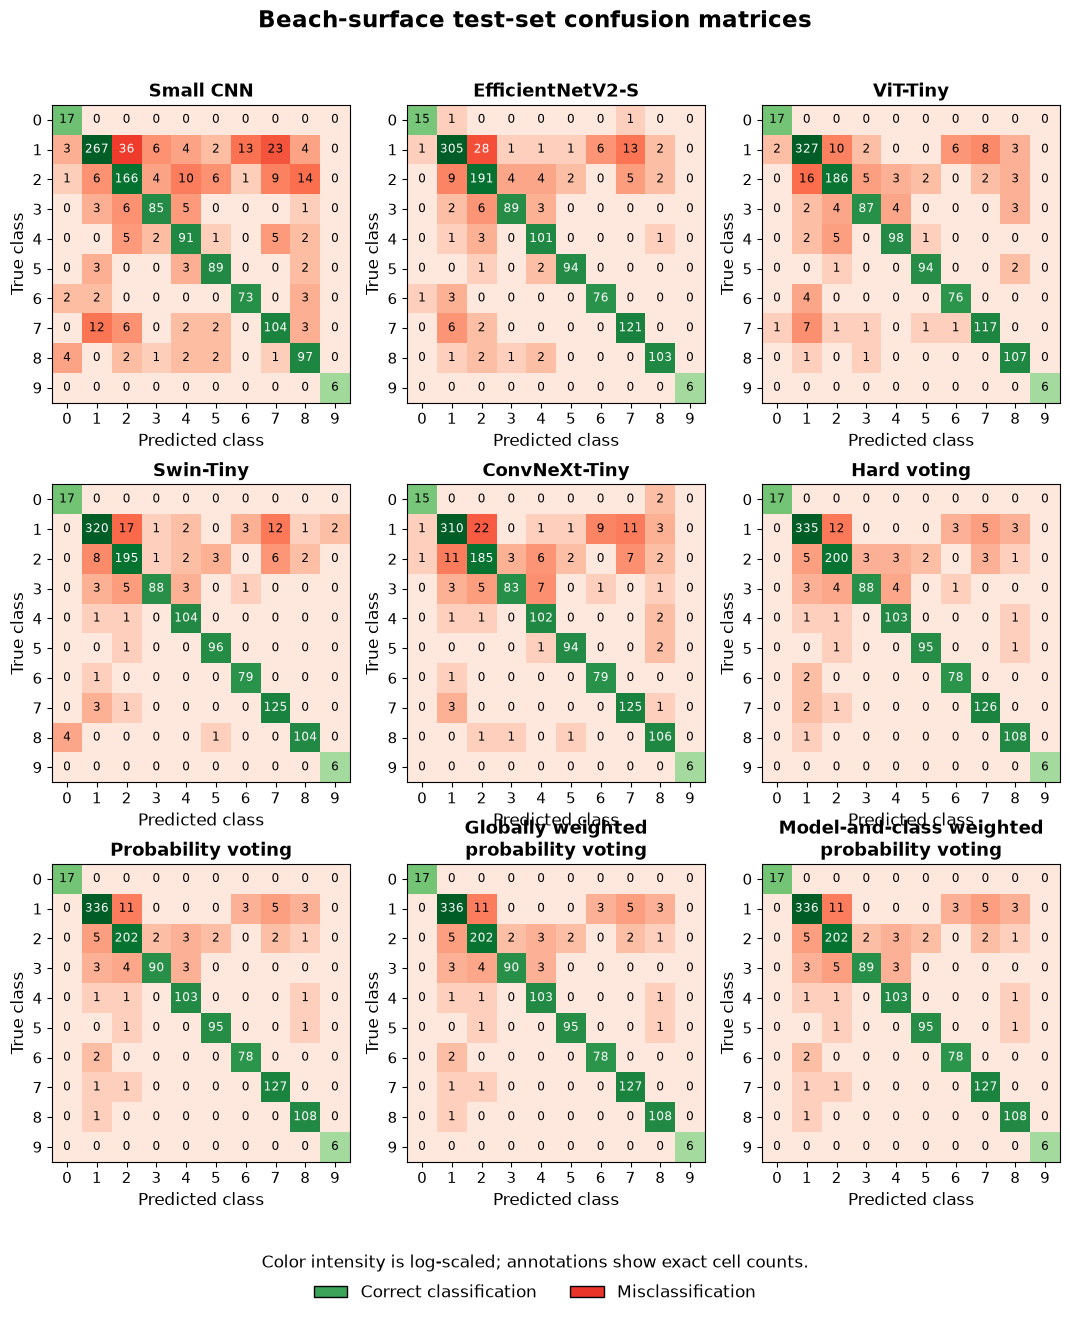

In [4]:
confusion_figure = plot_exact_confusion_matrices(
    confusion_matrices,
    CLASS_CODES,
    "Beach-surface test-set confusion matrices",
    panel_size=3.6,
    font_scale=1.20,
)
plt.show()

In [5]:
print_latex_metric_tables(
    aggregate_metrics,
    selected_per_class_metrics,
    confusion_matrices,
    CLASS_CODES,
    dataset_label="beach-surface classification dataset",
    label_prefix="beach-surface",
    per_class_method_label=DETAILED_ENSEMBLE_NAME,
)

% Aggregate metrics
\begin{longtable}{lrrrrr}
\caption{Aggregated test-set metrics for the beach-surface classification dataset.} \label{tab:beach-surface-aggregate-metrics} \\
\toprule
\textbf{Method} & \textbf{Acc.} & \textbf{Prec.} & \textbf{Rec.} & \textbf{F1-score} & \textbf{MCC} \\
\midrule
\endfirsthead
\caption[]{Aggregated test-set metrics for the beach-surface classification dataset.} \\
\toprule
\textbf{Method} & \textbf{Acc.} & \textbf{Prec.} & \textbf{Rec.} & \textbf{F1-score} & \textbf{MCC} \\
\midrule
\endhead
\midrule
\multicolumn{6}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
Small CNN & 0.816 & 0.815 & 0.875 & 0.839 & 0.785 \\
EfficientNetV2-S & 0.903 & 0.918 & 0.926 & 0.921 & 0.885 \\
ViT-Tiny & 0.915 & 0.920 & 0.937 & 0.928 & 0.898 \\
Swin-Tiny & 0.930 & 0.907 & 0.955 & 0.928 & 0.917 \\
ConvNeXt-Tiny & 0.906 & 0.913 & 0.929 & 0.919 & 0.890 \\
\midrule
Hard voting & 0.948 & 0.959 & 0.963 & 0.961 & 0.938 \\
Probability voting & \cellcolor{

In [6]:
print_latex_best_backbones_by_class(
    per_class_metrics,
    dataset_label="beach-surface classification dataset",
    label_prefix="beach-surface",
)

% Best standalone backbone by class and metric
\begin{longtable}{@{}rlccccc@{}}
\caption{Standalone backbones achieving the highest class-specific F1-score in the beach-surface classification dataset. An X identifies the best result; exact ties are retained.} \label{tab:beach-surface-best-backbone-per-class} \\
\toprule
\textbf{Class} & \textbf{Class name} & \shortstack{\textbf{Small}\\\textbf{CNN}} & \shortstack{\textbf{EfficientNet}\\\textbf{V2-S}} & \shortstack{\textbf{ViT}\\\textbf{Tiny}} & \shortstack{\textbf{Swin}\\\textbf{Tiny}} & \shortstack{\textbf{ConvNeXt}\\\textbf{Tiny}} \\
\midrule
\endfirsthead
\caption[]{Standalone backbones achieving the highest class-specific F1-score in the beach-surface classification dataset.} \\
\toprule
\textbf{Class} & \textbf{Class name} & \shortstack{\textbf{Small}\\\textbf{CNN}} & \shortstack{\textbf{EfficientNet}\\\textbf{V2-S}} & \shortstack{\textbf{ViT}\\\textbf{Tiny}} & \shortstack{\textbf{Swin}\\\textbf{Tiny}} & \shortstack{\textbf{ConvNe

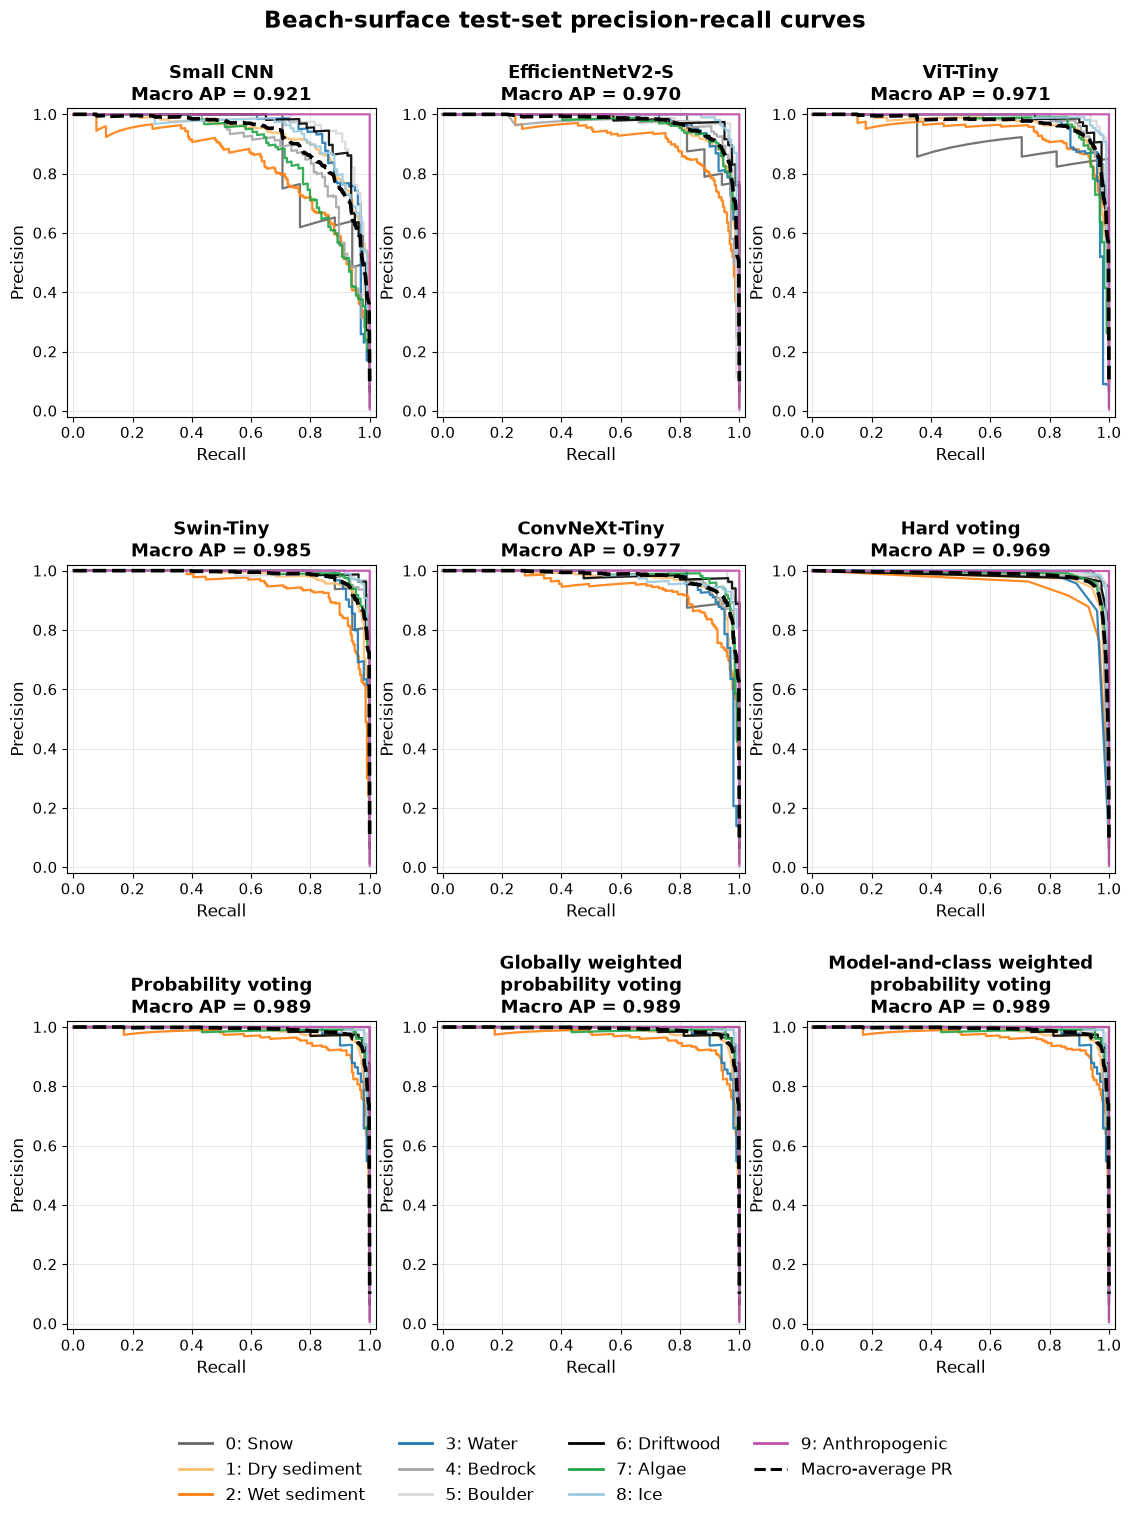

In [7]:
precision_recall_figure = plot_multiclass_precision_recall_curves(
    predictions,
    CLASS_CODES,
    CLASS_NAMES,
    "Beach-surface test-set precision-recall curves",
    panel_size=3.6,
    font_scale=1.20,
)
plt.show()

In [8]:
best_grid_search_configurations = load_best_grid_search_configurations(METHOD_SPECS)
display(
    best_grid_search_configurations.style.format(
        {
            "Learning rate": "{:.0e}",
            "Weight decay": "{:.0e}",
            "Dropout": "{:g}",
            "Validation macro F1": "{:.3f}",
        },
        na_rep="--",
    )
)
print_latex_best_grid_search_configurations(
    best_grid_search_configurations,
    dataset_label="beach-surface classification dataset",
    label_prefix="beach-surface",
)

,Model,Learning rate,Weight decay,Dropout,Context radius,Validation macro F1
0,Small CNN,3e-05,1e-04,0.25,1,0.822
1,EfficientNetV2-S,1e-04,1e-03,0.3,1,0.911
2,ViT-Tiny,1e-04,1e-04,0,2,0.931
3,Swin-Tiny,1e-04,1e-04,0,2,0.946
4,ConvNeXt-Tiny,3e-05,1e-03,--,2,0.929


% Best-performing grid-search configurations
\begin{longtable}{@{}lrrrrr@{}}
\caption{Best-performing grid-search configurations for the beach-surface classification dataset, selected according to macro-averaged F1-score on the validation set.} \label{tab:beach-surface-best-grid-search-configurations} \\
\toprule
\textbf{Model} & \shortstack{\textbf{Learning}\\\textbf{rate}} & \shortstack{\textbf{Weight}\\\textbf{decay}} & \textbf{Dropout} & \shortstack{\textbf{Context}\\\textbf{radius}} & \shortstack{\textbf{Validation}\\\textbf{F1-score}} \\
\midrule
\endfirsthead
\caption[]{Best-performing grid-search configurations for the beach-surface classification dataset.} \\
\toprule
\textbf{Model} & \shortstack{\textbf{Learning}\\\textbf{rate}} & \shortstack{\textbf{Weight}\\\textbf{decay}} & \textbf{Dropout} & \shortstack{\textbf{Context}\\\textbf{radius}} & \shortstack{\textbf{Validation}\\\textbf{F1-score}} \\
\midrule
\endhead
\midrule
\multicolumn{6}{r}{Continued on next page} \\
\midru